# SWEET watermark comparison

Qwen 1.5B on all 164 HumanEval problems, with SWEET strengths 1, 2, and 3. Entropy cutoff: 0.9 nats; gamma: 0.25. Generation and detection completed on 13 October 2026; Docker correctness evaluation completed on 18 October 2026. Saved results are shown below.


## Environment

Colab GPU execution from VS Code, with pinned dependencies and Drive checkpoints. SWEET generation and detection both use Qwen.


In [9]:
from pathlib import Path
import json, os, shutil, subprocess, sys, zipfile
from IPython.display import Image, Markdown, display

USE_VSCODE = True  # False enables Colab browser upload/download dialogs.
USE_DRIVE = True  # False uses temporary storage; download results before leaving.
READY = False
if not Path('/content').is_dir():
    raise RuntimeError('This notebook uses a Google Colab GPU runtime.')
from google.colab import drive, files
if not shutil.which('nvidia-smi'):
    raise RuntimeError('Select a GPU using Select Kernel > Colab > New Colab Server, then rerun.')
DRIVE_ROOT = None
if USE_DRIVE:
    try:
        drive.mount('/content/drive')
    except Exception as exc:
        raise RuntimeError('Drive authorization failed. In VS Code, run Colab: Mount Google Drive to Server, '
                           'execute its added cell and retry; or set USE_DRIVE=False for temporary storage.') from exc
    DRIVE_ROOT = Path('/content/drive/MyDrive/CodeGuardLLM/colab-sweet')
    DRIVE_ROOT.mkdir(parents=True, exist_ok=True)

PROJECT = Path('/content/CodeGuardLLM-SWEET')
BUNDLE = Path('/content/codeguard-sweet-colab.zip')
if not (PROJECT / 'src/codeguard/sweet.py').is_file():
    saved_bundle = DRIVE_ROOT / BUNDLE.name if DRIVE_ROOT else None
    if not BUNDLE.is_file() and saved_bundle and saved_bundle.is_file():
        shutil.copyfile(saved_bundle, BUNDLE)
    if not BUNDLE.is_file():
        if USE_VSCODE:
            raise FileNotFoundError('In VS Code Explorer, right-click .tmp/codeguard-sweet-colab.zip > Upload to Colab. '
                                    'Wait for upload to finish, then rerun this cell.')
        print('Select codeguard-sweet-colab.zip from your laptop.')
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise RuntimeError('Select only the project ZIP.')
        BUNDLE.write_bytes(next(iter(uploaded.values())))
        del uploaded
    with zipfile.ZipFile(BUNDLE) as archive:
        for item in archive.infolist():
            target = (PROJECT.parent / item.filename).resolve()
            if (not target.is_relative_to(PROJECT) or '\\' in item.filename
                    or (item.external_attr >> 16) & 0o170000 == 0o120000):
                raise ValueError('Invalid project archive path')
        if 'CodeGuardLLM-SWEET/src/codeguard/sweet.py' not in archive.namelist():
            raise ValueError('Use the newly prepared codeguard-sweet-colab.zip.')
        archive.extractall(PROJECT.parent)
    if saved_bundle:
        shutil.copyfile(BUNDLE, saved_bundle)
os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT / 'src'))
from codeguard.cloud import Checkpoint
ENV = PROJECT / '.venv-colab'
PYTHON = str(ENV / 'bin/python')
CHECKPOINT = None
print('Project:', PROJECT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/CodeGuardLLM-SWEET


In [10]:
from collections import deque
from datetime import datetime, timezone
import os, subprocess

LOG_DIR = PROJECT / '.tmp/notebook-logs'
LOG_DIR.mkdir(parents=True, exist_ok=True)

def command(args, label='command'):
    log = LOG_DIR / (label + '-' + datetime.now(timezone.utc).strftime('%Y%m%d-%H%M%S-%f') + '.log')
    tail = deque(maxlen=30)
    print(f'Running {label}. Log: {log}', flush=True)
    with log.open('w', encoding='utf-8') as handle:
        with subprocess.Popen(
            list(map(str, args)), cwd=PROJECT, stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace',
            bufsize=1, env={**os.environ, 'PYTHONUNBUFFERED': '1', 'MPLBACKEND': 'Agg'},
        ) as process:
            try:
                for line in process.stdout:
                    print(line, end='', flush=True)
                    handle.write(line)
                    handle.flush()
                    tail.append(line)
                    if CHECKPOINT is not None:
                        CHECKPOINT.save()
                status = process.wait()
            except BaseException:
                process.terminate()
                try:
                    process.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    process.kill()
                    process.wait()
                raise
            finally:
                if CHECKPOINT is not None:
                    CHECKPOINT.save(force=True)
    if status:
        detail = ''.join(tail)
        raise RuntimeError(f'{label} failed (exit {status}). Full log: {log}\n\n{detail}')

def run(*args, label='codeguard'):
    command([PYTHON, '-u', *args], label=label)

In [11]:
READY = False
# virtualenv supplies pip even when Colab's Python has no ensurepip.
if not Path(PYTHON).is_file():
    command([sys.executable, '-m', 'pip', 'install', 'virtualenv'], label='environment-tool')
    command([sys.executable, '-m', 'virtualenv', str(ENV)], label='environment')
command([sys.executable, '-m', 'pip', '--python', PYTHON, 'install', '--upgrade', 'pip'], label='pip')
run('-m', 'pip', 'install', 'torch==2.8.0', '--index-url', 'https://download.pytorch.org/whl/cu126', label='pytorch')
run('-m', 'pip', 'install', '-e', '.[ml,data,analysis]', label='dependencies')
run('scripts/bootstrap_markllm.py', label='markllm')

run('-c', """
import json
from pathlib import Path
import torch, yaml
from codeguard.backend import HFBackend
from codeguard.cloud import select_dtype
from codeguard.config import load_config, portable_config
from codeguard.storage import digest
assert torch.cuda.is_available(), 'Select a Colab GPU runtime before continuing'
config = load_config('configs/sweet.yaml')
config['model']['dtype'] = select_dtype(torch.cuda.get_device_capability()[0], torch.cuda.is_bf16_supported())
x = torch.ones((16,16), device='cuda', dtype=getattr(torch, config['model']['dtype']))
assert torch.isfinite(x @ x).all().item(), 'GPU calculation failed'
print('GPU:', torch.cuda.get_device_name(), '| Precision:', config['model']['dtype'])
backend = HFBackend(config, load_model=False)
metadata = backend.metadata
Path('.tmp/sweet-colab.yaml').write_text(yaml.safe_dump(config), encoding='utf-8')
Path('.tmp/sweet-colab-runtime.json').write_text(json.dumps({'id': digest({'backend': metadata, 'config': portable_config(config)})[:16], 'backend': metadata}), encoding='utf-8')

# Short setup check only; these outputs never enter experiment results.
config['generation']['max_new_tokens'] = 16
checks = []
for condition in ('clean', 'watermarked'):
    sample = backend.generate('Write a Python function add(a, b) returning a + b.', 'setup/sweet', 42, condition)
    score = backend.score(sample['raw_text'])
    assert score['status'] in ('ok', 'too_short', 'no_eligible_tokens')
    checks.append({'condition': condition, 'tokens': sample['generated_tokens'], 'score_status': score['status']})
    print('SWEET setup check:', checks[-1])
Path('.tmp/sweet-preflight.json').write_text(json.dumps({'purpose': 'setup smoke test, not research results', 'checks': checks}), encoding='utf-8')
""", label='gpu-and-detector')
CONFIG = PROJECT / '.tmp/sweet-colab.yaml'
runtime = json.loads((PROJECT / '.tmp/sweet-colab-runtime.json').read_text())
RUN_DIR = PROJECT / 'runs/colab' / runtime['id'] / 'sweet_comparison'
backup = DRIVE_ROOT / runtime['id'] / 'results.zip' if DRIVE_ROOT else None
CHECKPOINT = Checkpoint(RUN_DIR, backup, PROJECT / '.tmp/checkpoints')
CHECKPOINT.restore()
RUN_DIR.mkdir(parents=True, exist_ok=True)
shutil.copyfile(CONFIG, RUN_DIR / 'sweet-colab.yaml')
(RUN_DIR / 'runtime.json').write_text(json.dumps(runtime, indent=2), encoding='utf-8')
CHECKPOINT.save(force=True)
run('-m', 'codeguard', 'validate', '--config', CONFIG, '--check-markllm', label='validate')
READY = True
print('Results:', RUN_DIR)
print('Drive checkpoint:', backup if backup else 'disabled: temporary storage only')

Running pip. Log: /content/CodeGuardLLM-SWEET/.tmp/notebook-logs/pip-20261013-141846-566299.log
Running pytorch. Log: /content/CodeGuardLLM-SWEET/.tmp/notebook-logs/pytorch-20261013-141848-142656.log
Looking in indexes: https://download.pytorch.org/whl/cu126
Running dependencies. Log: /content/CodeGuardLLM-SWEET/.tmp/notebook-logs/dependencies-20261013-141848-830045.log
Obtaining file:///content/CodeGuardLLM-SWEET
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for codeguardllm (pyproject.toml): started
  Building editable for

## Samples

The experiment contains 984 completions: 164 problems × 2 conditions × 3 runs. Existing samples are reused when resuming.

In [12]:
if not globals().get('READY', False):
    raise RuntimeError('Setup has not completed.')
run('scripts/compare_watermarks.py', 'generate', '--config', CONFIG, '--output', RUN_DIR, label='sweet-generation')


Running sweet-generation. Log: /content/CodeGuardLLM-SWEET/.tmp/notebook-logs/sweet-generation-20261013-141916-267920.log

Experiment: delta-1
Already complete: 328 samples in /content/CodeGuardLLM-SWEET/runs/colab/0eedc6730e049860/sweet_comparison/delta-1

Experiment: delta-2
Already complete: 328 samples in /content/CodeGuardLLM-SWEET/runs/colab/0eedc6730e049860/sweet_comparison/delta-2

Experiment: delta-3
Already complete: 328 samples in /content/CodeGuardLLM-SWEET/runs/colab/0eedc6730e049860/sweet_comparison/delta-3
Checkpoint saved: results.zip


## Reference controls

SWEET scores 164 HumanEval reference solutions using Qwen probabilities. Scores are shared across strengths within this SWEET run. Reference code is never executed during scoring.


In [13]:
run('scripts/compare_watermarks.py', 'controls', '--config', CONFIG, '--output', RUN_DIR, label='reference-controls')


Running reference-controls. Log: /content/CodeGuardLLM-SWEET/.tmp/notebook-logs/reference-controls-20261013-141925-721844.log
Already scored: 164 reference solutions
Checkpoint saved: results.zip


## Correctness

The saved report below includes local Docker evaluation of all 984 generated solutions on 18 October 2026, using the original HumanEval task snapshots. All 164 reference solutions passed at each strength. No generation or watermark scoring was repeated. Each solution had a 5-second timeout and 256 MiB memory limit.

The report cells were executed locally against `runs/sweet-import/0eedc6730e049860/sweet_comparison`; earlier outputs retain their original Colab execution history. The Colab workflow itself still defers correctness testing to Docker after export. Rerunning analysis on the original unevaluated Colab checkpoint will show correctness as pending.


## Results

Tables and plots use saved SWEET scores. Detection uses code alone; prompt removal may change early entropy estimates. No eligible tokens means unscorable.


Core report saved: C:\Users\user\github\CodeGuardLLM\runs\sweet-import\0eedc6730e049860\sweet_comparison\analysis\report.md (complete)


| Strength | AUROC vs clean | AUROC vs reference | Clean Pass@1 | Watermarked Pass@1 | Change |
|---|---|---|---|---|---|
| 1 | 0.560 | 0.456 | 0.671 | 0.622 | -0.049 |
| 2 | 0.644 | 0.549 | 0.671 | 0.585 | -0.085 |
| 3 | 0.730 | 0.652 | 0.671 | 0.567 | -0.104 |

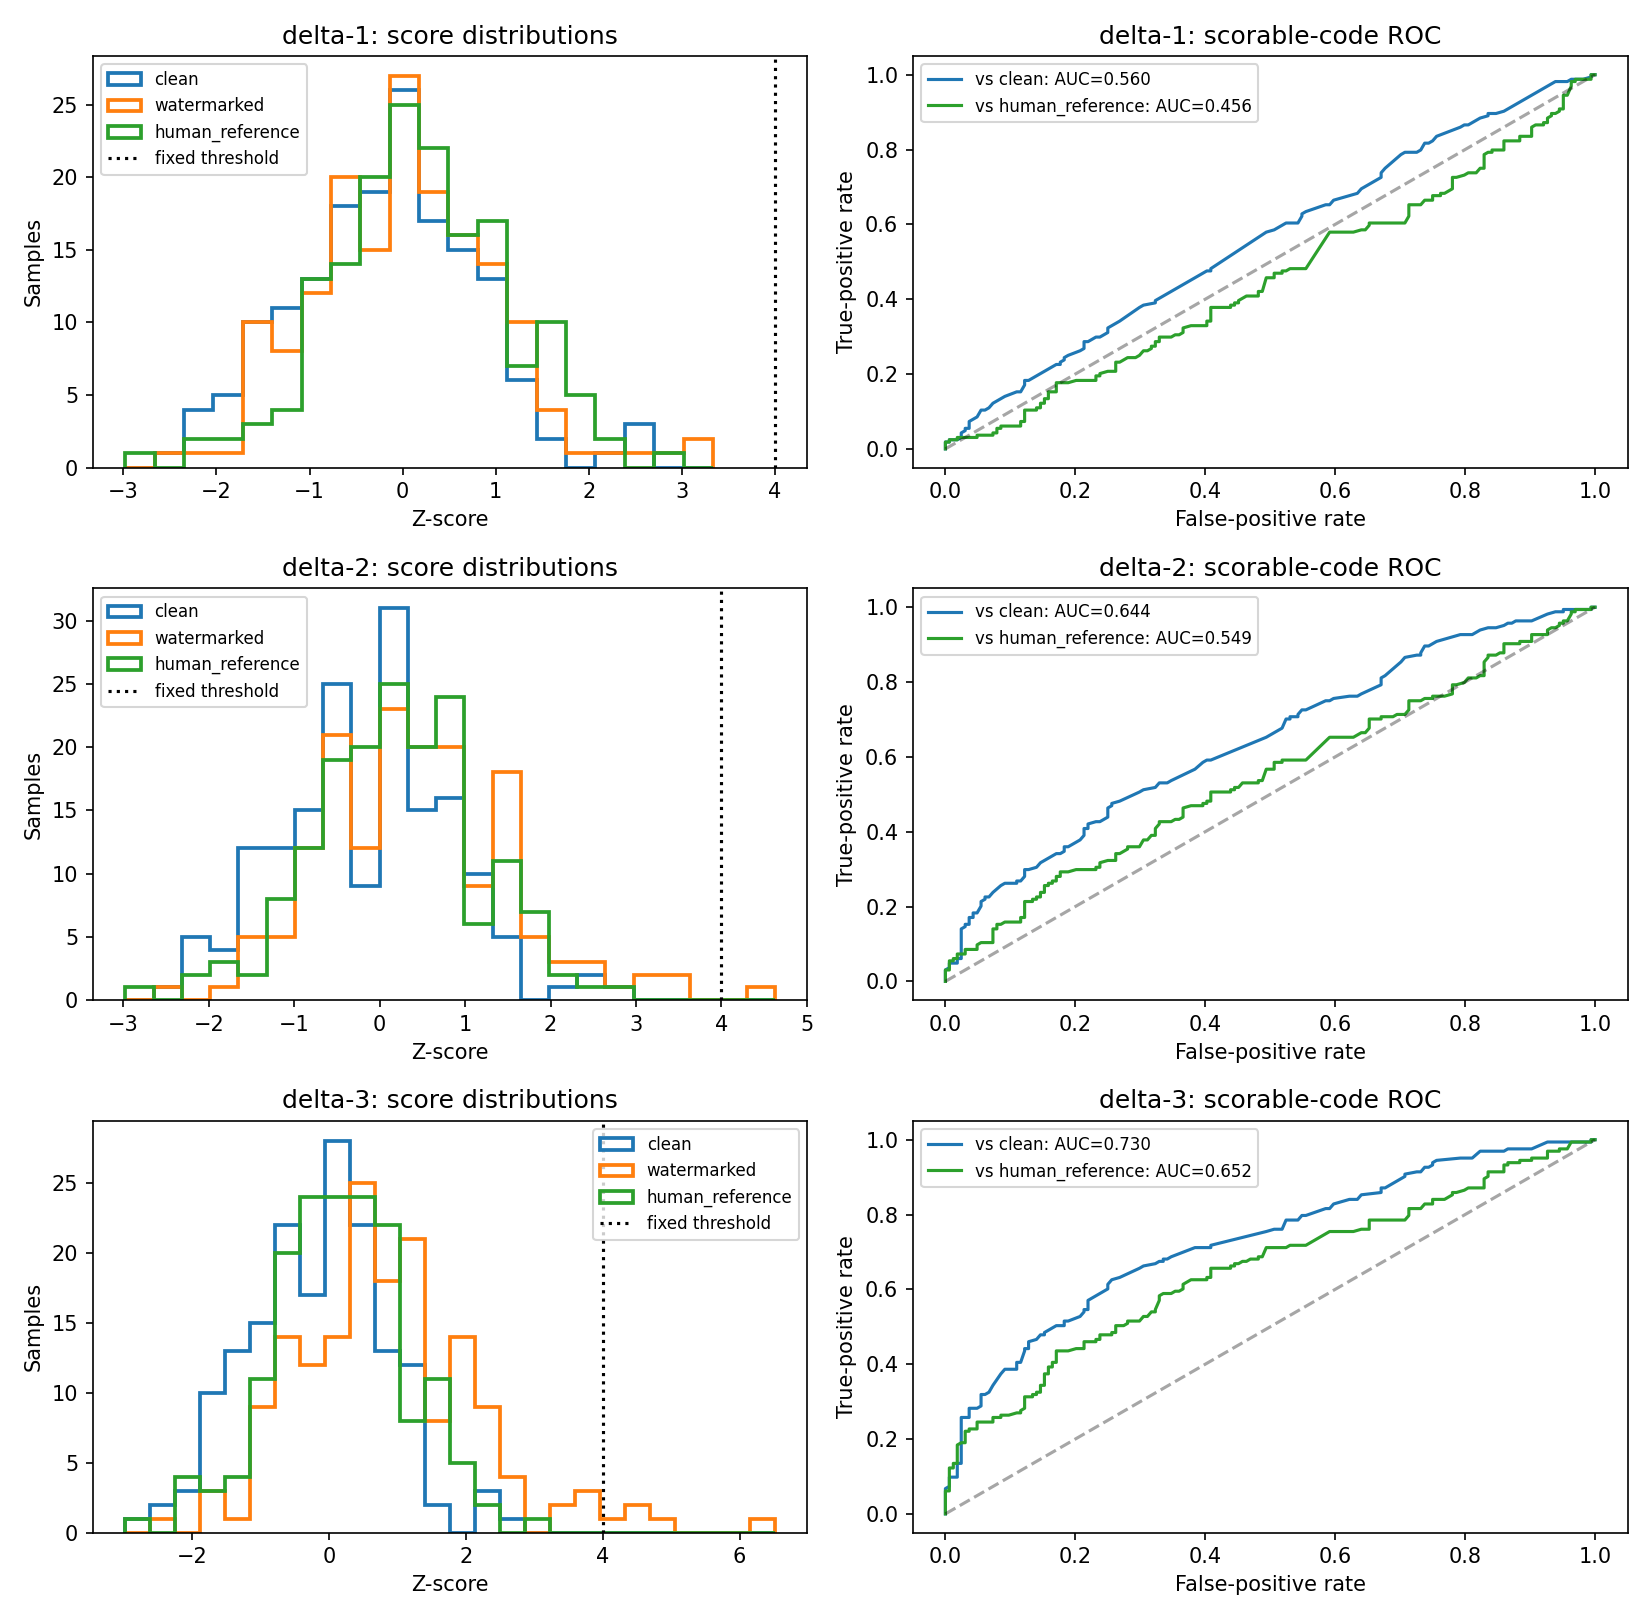

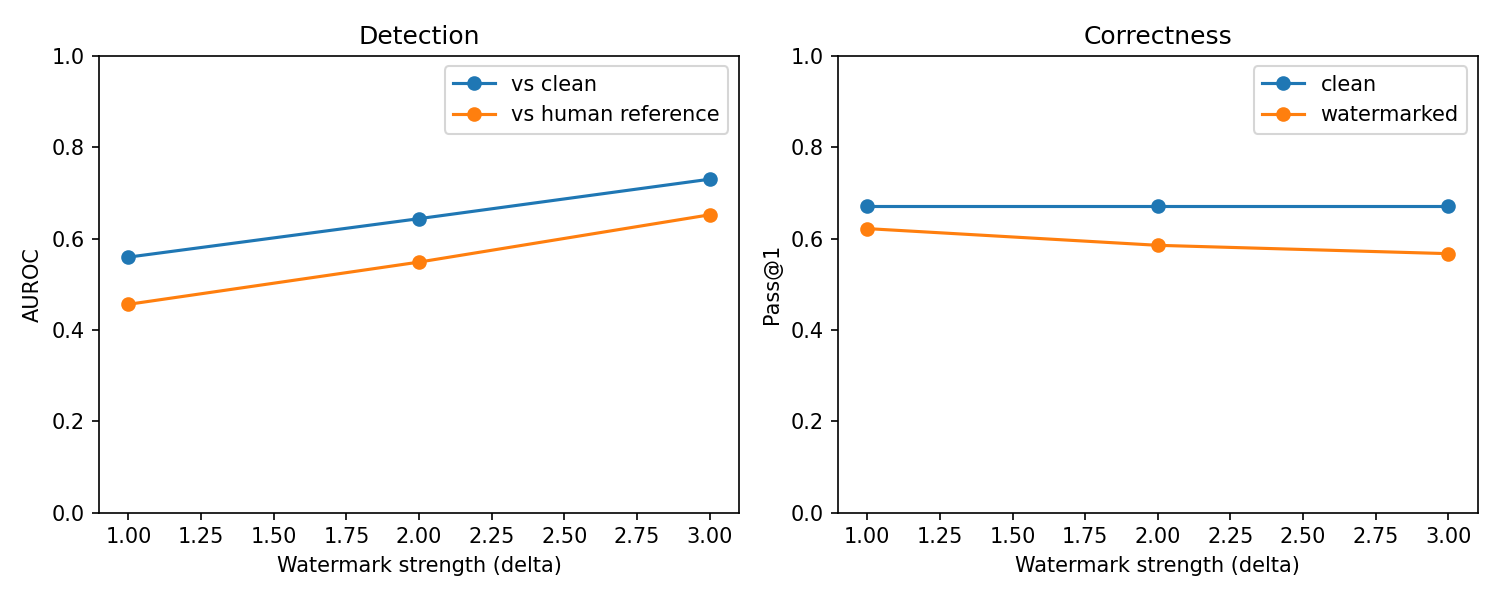

Report status: complete
Written report: C:\Users\user\github\CodeGuardLLM\runs\sweet-import\0eedc6730e049860\sweet_comparison\analysis\report.md


In [ ]:
run('scripts/compare_watermarks.py', 'analyze', '--config', CONFIG, '--output', RUN_DIR, label='core-analysis')
summary = json.loads((RUN_DIR / 'analysis/core_summary.json').read_text(encoding='utf-8'))
def number(value):
    return 'pending / unavailable' if value is None else f'{value:.3f}'
table = ['| Strength | AUROC vs clean | AUROC vs reference | Clean Pass@1 | Watermarked Pass@1 | Change |',
         '|---|---|---|---|---|---|']
for row in summary['comparison']:
    table.append(f"| {row['delta']:g} | {number(row['auroc_vs_clean'])} | {number(row['auroc_vs_human_reference'])} | "
                 f"{number(row['clean_pass_at_1'])} | {number(row['watermarked_pass_at_1'])} | {number(row['pass_at_1_change'])} |")
display(Markdown('\n'.join(table)))
display(Image(filename=str(RUN_DIR / 'analysis/controls_detection.png')))
display(Image(filename=str(RUN_DIR / 'analysis/tradeoff.png')))
print('Report status:', summary['status'])
print('Written report:', RUN_DIR / 'analysis/report.md')


## Correctness among detected solutions

Only watermarked outputs above the Z threshold enter conditional correctness. Joint success counts outputs that are both detected and correct among all watermarked outputs. Small detected groups limit interpretation.

In [ ]:
detected_summary = json.loads((RUN_DIR / 'analysis/core_summary.json').read_text(encoding='utf-8'))

def percent(value):
    return 'N/A / pending' if value is None else f'{100 * value:.1f}%'

table = ['| Strength | Threshold | Detected / generated | Evaluated detected | Correct detected | Correctness among detected | Both correct and detected / all |',
         '|---|---|---|---|---|---|---|']
for row in detected_summary['detected_correctness']:
    table.append(f"| {row['delta']:g} | Z > {row['threshold']:g} | {row['detected']}/{row['samples']} | "
                 f"{row['evaluated_detected']} | {row['correct_detected']} | "
                 f"{percent(row['correctness_among_detected'])} | {percent(row['correct_and_detected_rate'])} |")
display(Markdown('\n'.join(table)))
print('N/A: no detections; pending: required generation or tests are incomplete. Correct counts use completed tests.')


| Strength | Threshold | Detected / generated | Evaluated detected | Correct detected | Correctness among detected | Both correct and detected / all |
|---|---|---|---|---|---|---|
| 1 | Z > 4 | 0/164 | 0 | 0 | N/A / pending | 0.0% |
| 2 | Z > 4 | 1/164 | 1 | 1 | 100.0% | 0.6% |
| 3 | Z > 4 | 5/164 | 5 | 1 | 20.0% | 0.6% |

N/A: no detections; pending: required generation or tests are incomplete. Correct counts use completed tests.


## Saved experiment

The archive contains samples, manifests, tables, and plots.

In [16]:
# This cell also exports completed samples after an interrupted generation.
if not any(RUN_DIR.glob('*/generations.jsonl')):
    print('No samples saved yet.')
else:
    CHECKPOINT.save(force=True)
    EXPORT = shutil.make_archive(str(PROJECT.parent / 'codeguard-sweet-results'), 'zip', RUN_DIR.parent, RUN_DIR.name)
    print('Results archive:', EXPORT)
    if USE_VSCODE:
        print('In the VS Code Colab sidebar > Contents, refresh, then right-click codeguard-sweet-results.zip > Download...')
    else:
        files.download(EXPORT)

Checkpoint saved: results.zip
Results archive: /content/codeguard-sweet-results.zip
In the VS Code Colab sidebar > Contents, refresh, then right-click codeguard-sweet-results.zip > Download...
